In [1]:
#!pip install google-cloud-storage
#!pip install --upgrade google-cloud-storage

In [2]:
import sys
import os
CURRENT_BASE_DIR = '/home/jupyter/ICL/'
sys.path.append(CURRENT_BASE_DIR+"src/")
os.environ['TRANSFORMERS_CACHE'] = CURRENT_BASE_DIR+'SRF_experiments/cache/'
os.environ['HF_HOME'] = CURRENT_BASE_DIR+'SRF_experiments/cache/'
os.environ['MPLCONFIGDIR'] = CURRENT_BASE_DIR+'SRF_experiments/cache/'
local_downloads_tmp_data_path = CURRENT_BASE_DIR+'SRF_experiments/temp/'

In [3]:
import yaml
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

In [4]:
# Use only 1 GPU if available
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import time
import itertools
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset

In [5]:
from iAmTime.pipeline import iAmTimePipeline
import torch

# Download Model From GCS

In [6]:
IAMTIME_SAVE_PATH = "/home/jupyter/chronos-forecasting/SRF_experiments/ICL/SRF_experiments/output/iamtime-checkpoint"
original_model_name = "iAmTime"

# When True, reuse the model files already present at IAMTIME_SAVE_PATH and skip the
# GCS download in the next cell. When False -- or when any required file is missing --
# the next cell downloads from GCS and overwrites. Flip to True on subsequent runs to
# avoid re-downloading the checkpoint.
USE_CACHED_MODEL = True

# chronos_bolt_icl
# iAmTime_run1_50000
# iAmTime_run2_80000
# iAmTime

In [7]:
##### Download Weights from GCS #####

from google.cloud import storage
import base64
import json
from pathlib import Path
Path(IAMTIME_SAVE_PATH).mkdir(parents=True, exist_ok=True)

gcs_creds_enc_file = CURRENT_BASE_DIR+'SRF_experiments/encoded.txt'

def setup_gs_client():
    with open(gcs_creds_enc_file, 'r') as f:
        b64_creds = f.read()
    message = base64.b64decode(b64_creds).decode('utf-8')
    # base64_bytes = base64.b64decode(base64_secret)
    # message = base64_bytes.decode('utf-8')
    data_json = json.loads(message)
    client = storage.Client.from_service_account_info(data_json)
    return client

def download_to_local(bucket_name, bucket_file_name, local_file_name):
    storage_client = setup_gs_client()
    bucket = storage_client.bucket(bucket_name)
    blob = bucket.blob(bucket_file_name)
    # If local_file_name is just a filename (no directory), save to local_downloads_tmp_data_path
    if os.path.dirname(local_file_name):
        # local_file_name contains a directory, use as is
        save_path = local_file_name
    else:
        # just a filename, prepend the tmp path
        save_path = local_downloads_tmp_data_path + local_file_name
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    blob.download_to_filename(save_path)

REQUIRED_MODEL_FILES = ["config.json", "model.safetensors"]

if USE_CACHED_MODEL and all(Path(IAMTIME_SAVE_PATH, fn).exists() for fn in REQUIRED_MODEL_FILES):
    print(f"USE_CACHED_MODEL=True and all files cached at {IAMTIME_SAVE_PATH}; skipping download.")
else:
    for fn in REQUIRED_MODEL_FILES:
        download_to_local(
            bucket_name="adtech-ds-artifacts-dev", 
            bucket_file_name="ds/forecast/demand_forecast/ltm/models/"+original_model_name+"/"+fn, 
            local_file_name=IAMTIME_SAVE_PATH+'/'+fn
        )
    print("Model Downloaded Locally to:",IAMTIME_SAVE_PATH)

USE_CACHED_MODEL=True and all files cached at /home/jupyter/chronos-forecasting/SRF_experiments/ICL/SRF_experiments/output/iamtime-checkpoint; skipping download.


In [8]:
# Load the iAmTime pipeline
# For GPU inference, use device_map="cuda"
pipeline = iAmTimePipeline.from_pretrained(
    IAMTIME_SAVE_PATH,
    torch_dtype=torch.float32,
    device_map="cuda",
)

`torch_dtype` is deprecated! Use `dtype` instead!
`torch_dtype` is deprecated! Use `dtype` instead!


## Load Walmart data — INTERNAL-HOLDOUT evaluation

HuggingFace dataset `autogluon/fev_datasets` configuration `walmart` -- the
same source used by `iAmTime-with-examples.ipynb`. Each item is a
`(Store, Dept)` weekly time series with a univariate `target` and 10 native
exogenous channels shared between past and future:

`MarkDown1..5`, `Fuel_Price`, `Temperature`, `CPI`, `Unemployment`, `IsHoliday`.

Evaluation is a simple INTERNAL-HOLDOUT: the last `prediction_length = 39`
weekly samples of each item's `target` are held out as ground truth; iAmTime
is fed `target[:-prediction_length]` and asked to predict the held-out window.
Pipeline calls are batched by `model_batch_size = 16` for throughput; per-item
metrics and forecast tensors are collected silently for the aggregate table
(cell 24) and multiplot (cell 26).

Four demo categories, mirroring `iAmTime-IMS-forecast-demo-eval.ipynb`:

- **Zero-shot** -- no covariates, no examples.
- **10 Covariates (no ex)** -- all 10 native Walmart covariates as past + future
  covariates, no examples.
- **3 In-series Examples (no cov)** -- 3 random-length windows sampled from each
  item's own target (no covariates), padded within each batch to
  `max_hist_len_in_batch`, following the reference notebook's semantics.
- **10 Covariates + 3 Examples** -- combined.

Knobs (cell 10):
- `MAX_ITEMS = None` evaluates the full dataset. Set to a small int (e.g. 200)
  for a smoke test.
- `MAX_BATCHES = None` runs all batches. Set to a small int (e.g. 5) to
  reproduce the reference notebook's fast preview.
- `DEBUG_DIAGNOSTICS = False` suppresses per-batch tensor-shape dumps. Flip to
  True while debugging ICL-input shape issues.


In [9]:
# Global debug switch. When False (default) the per-batch tensor-structure
# dumps produced by `_diagnose_icl_inputs`, `_diagnose_forecast_outputs`, and
# other verbose prints in cells 16 / 18 / 20 / 22 are suppressed. Flip to True
# while debugging shape / ICL-input issues.
DEBUG_DIAGNOSTICS = False


# Reproducibility seed for random example-window sampling in cells 20 / 22.
# Reseeded at the top of each ex-* cell so re-running that cell alone is
# deterministic regardless of any random calls in prior cells.
SEED = 0


# HuggingFace source dataset (same as `iAmTime-with-examples.ipynb`).
DATASET_PATH = "autogluon/fev_datasets"
DATASET_CONFIG = "walmart"

# Native Walmart covariates. Past & future channels are identical for this
# dataset -- the 10 native covariates are supplied for both windows.
target_column_name = "target"
past_covariates_names = [
    "MarkDown2", "Unemployment", "MarkDown4", "Fuel_Price", "MarkDown1",
    "Temperature", "MarkDown5", "MarkDown3", "CPI", "IsHoliday",
]
future_covariates_names = list(past_covariates_names)

# Weekly Walmart data. 39-step (~9-month) horizon matches the reference notebook.
prediction_length = 39
# MASE seasonality: reference notebook uses gluonts default (season_length=1
# -> naive baseline is one-step lag). Kept identical for metric parity.
seasonality_mase = 1
# Pipeline batch size and quantile levels used across every category below.
model_batch_size = 16
quantile_levels = [0.1, 0.5, 0.9]

# Optional caps for smoke tests / quick iterations. Setting either to None
# evaluates the full dataset. Both scale cleanly to thousands of items.
MAX_ITEMS = None
MAX_BATCHES = None


data = load_dataset(DATASET_PATH, DATASET_CONFIG)["train"]
items = list(itertools.islice(data, MAX_ITEMS)) if MAX_ITEMS is not None else list(data)


def _item_key(idx):
    """Stable per-item identifier used as dict key across every category."""
    return f"i{idx:05d}"


# Aggregate summary (constant intermediate output regardless of dataset size).
_lens = np.array([len(x[target_column_name]) for x in items], dtype=int)
_usable = int(np.sum(_lens > prediction_length))
print(
    f"Loaded {len(items)} items from {DATASET_PATH!r}:{DATASET_CONFIG!r}\n"
    f"  prediction_length={prediction_length}, model_batch_size={model_batch_size}, "
    f"num_past_cov={len(past_covariates_names)}, num_future_cov={len(future_covariates_names)}\n"
    f"  target length (weeks):  min={_lens.min()}, max={_lens.max()}, "
    f"mean={_lens.mean():.1f}, median={int(np.median(_lens))}\n"
    f"  usable (L > prediction_length): {_usable} / {len(items)}"
)


Loaded 2936 items from 'autogluon/fev_datasets':'walmart'
  prediction_length=39, model_batch_size=16, num_past_cov=10, num_future_cov=10
  target length (weeks):  min=86, max=143, mean=142.7, median=143
  usable (L > prediction_length): 2936 / 2936


In [10]:
# Walmart-specific input builders + batcher, ported from
# `iAmTime-with-examples.ipynb` so this eval notebook preserves the exact input
# semantics of that reference notebook. Every helper is purely functional:
# each call returns a fresh dict / list without mutating its inputs.


def _pack_model_items(
    items, prediction_length, target_column_name, past_covariates, future_covariates,
):
    """Yield `(model_input, truth)` per item, using a last-`prediction_length`
    INTERNAL-HOLDOUT split. `model_input` is the pipeline's target+covariates
    format:

        {"target": history[np.ndarray],
         "past_covariates":   {name: np.ndarray, ...}   # optional
         "future_covariates": {name: np.ndarray, ...}}  # optional

    (only the keys corresponding to non-None `past_covariates` /
    `future_covariates` are populated).
    """
    for item in items:
        history_len = len(item[target_column_name]) - prediction_length
        if history_len <= 0:
            continue
        model_input = {
            "target": np.asarray(item[target_column_name][:-prediction_length], dtype=float),
        }
        if past_covariates is not None:
            model_input["past_covariates"] = {
                c: np.asarray(item[c][:-prediction_length], dtype=float)
                for c in past_covariates
            }
        if future_covariates is not None:
            model_input["future_covariates"] = {
                c: np.asarray(item[c][-prediction_length:], dtype=float)
                for c in future_covariates
            }
        truth = np.asarray(item[target_column_name][-prediction_length:], dtype=float)
        yield model_input, truth


def _left_pad(arrays, pad_to, axis, value):
    """NaN-left-pad each entry of `arrays` to length `pad_to` along `axis` and
    stack. Preserves the reference notebook's shape invariants."""
    padded = []
    for arr in arrays:
        pad_width = [(0, 0)] * arr.ndim
        pad_len = pad_to - arr.shape[axis]
        if pad_len > 0:
            pad_width[axis] = (pad_len, 0)
            arr = np.pad(arr, pad_width, constant_values=value)
        padded.append(arr)
    return np.stack(padded, axis=0) if padded else np.asarray([])


def _create_examples_from_batch_and_pack_items(
    batch, prediction_length, num_examples,
    target_column_name, past_covariates, future_covariates, rng,
):
    """Yield `(icl_input, truth)` per item in `batch`, in the pipeline's
    ICL-attribute format. Follows the sampling / padding recipe from
    `_create_examples_from_batch_and_pack_items` in `iAmTime-with-examples.ipynb`:

      - For each item, sample `num_examples` random-length windows of size
        `[prediction_length + 1, target_len]`. Split each window into an example
        history (all-but-last-`prediction_length` samples) and an example future
        (last `prediction_length` samples).
      - Left-pad every example history AND the query history with NaN to
        `max_hist_len_in_batch` = max query-history length across the batch, so
        every entry in the batch shares the same tensor shape.
      - Covariate stacks (`example_exog_histories`, `example_exog_futures`,
        `query_exog_history`, `query_exog_future`) follow the same layout as
        the IMS eval notebook: axis-0 channel dim.

    Sampling uses the passed-in `rng` (`np.random.Generator`) for
    reproducibility.
    """
    query_packed = list(_pack_model_items(
        batch, prediction_length,
        target_column_name=target_column_name,
        past_covariates=past_covariates,
        future_covariates=future_covariates,
    ))
    if not query_packed:
        return
    max_hist_len_in_batch = max(len(qp[0]["target"]) for qp in query_packed)

    for model_input, truth in query_packed:
        target = model_input["target"]
        target_len = len(target)
        exog = model_input.get("past_covariates")
        fut_exog = model_input.get("future_covariates")

        min_win_len = prediction_length + 1
        num_exog = len(past_covariates) if past_covariates else 1

        if target_len < min_win_len:
            # Not enough data for even one valid example -> NaN placeholders.
            ex_target_hist = np.full((1, max_hist_len_in_batch), np.nan)
            ex_target_fut = np.full((1, prediction_length), np.nan)
            ex_exog_hist = np.full((1, num_exog, max_hist_len_in_batch), np.nan)
            ex_exog_fut = np.full((1, num_exog, prediction_length), np.nan)
        else:
            target_histories, target_futures = [], []
            exog_histories, exog_futures = [], []
            for _ in range(num_examples):
                win_len = int(rng.integers(min_win_len, target_len + 1))
                start = int(rng.integers(0, target_len - win_len + 1))
                hist_end = start + win_len - prediction_length
                end = start + win_len
                target_histories.append(target[start:hist_end])
                target_futures.append(target[hist_end:end])
                if exog is not None:
                    exog_histories.append(
                        np.stack([v[start:hist_end] for v in exog.values()], axis=0)
                    )
                    exog_futures.append(
                        np.stack([v[hist_end:end] for v in exog.values()], axis=0)
                    )
            ex_target_hist = _left_pad(
                [np.asarray(h, dtype=float) for h in target_histories],
                pad_to=max_hist_len_in_batch, axis=0, value=np.nan,
            )  # (num_examples, max_hist_len_in_batch)
            ex_target_fut = np.stack(
                [np.asarray(f, dtype=float) for f in target_futures], axis=0,
            )  # (num_examples, prediction_length)
            if exog is not None:
                ex_exog_hist = _left_pad(
                    exog_histories, pad_to=max_hist_len_in_batch, axis=1, value=np.nan,
                )  # (num_examples, num_exog, max_hist_len_in_batch)
                ex_exog_fut = np.stack(exog_futures, axis=0)
                # (num_examples, num_exog, prediction_length)
            else:
                ex_exog_hist = np.full((1, 1, max_hist_len_in_batch), np.nan)
                ex_exog_fut = np.full((1, 1, prediction_length), np.nan)

        # Query: left-pad target / exog history to max_hist_len_in_batch.
        q_target_hist = _left_pad(
            [np.asarray(target, dtype=float)],
            pad_to=max_hist_len_in_batch, axis=0, value=np.nan,
        )[0]
        if exog is not None:
            q_exog_hist = _left_pad(
                [np.stack([v for v in exog.values()], axis=0)],
                pad_to=max_hist_len_in_batch, axis=1, value=np.nan,
            )[0]
        else:
            q_exog_hist = np.full((1, max_hist_len_in_batch), np.nan)
        if fut_exog is not None:
            q_exog_fut = np.stack([v for v in fut_exog.values()], axis=0)
        else:
            q_exog_fut = np.full((1, prediction_length), np.nan)

        yield {
            "example_target_histories": ex_target_hist,
            "example_target_futures":   ex_target_fut,
            "example_exog_histories":   ex_exog_hist,
            "example_exog_futures":     ex_exog_fut,
            "query_target_history":     q_target_hist,
            "query_exog_history":       q_exog_hist,
            "query_exog_future":        q_exog_fut,
            "query_target_future":      np.array([]),
        }, truth


def _batched(iterable, batch_size):
    """Yield successive `batch_size`-length chunks from `iterable`."""
    it = iter(iterable)
    while True:
        chunk = list(itertools.islice(it, batch_size))
        if not chunk:
            return
        yield chunk


def _to_numpy_forecast(x):
    """Normalise a pipeline output element (torch tensor or ndarray) to a
    numpy array with the leading batch dim removed if present.

    Handles the two shapes iAmTime.predict_quantiles is observed to return
    per item:
      - `(prediction_length, num_quantiles)` -> pass-through
      - `(1, prediction_length, num_quantiles)` -> squeeze axis 0
      - `(1, prediction_length)` mean tensor -> squeeze axis 0
    """
    if hasattr(x, "cpu"):
        x = x.cpu()
    if hasattr(x, "numpy"):
        x = x.numpy()
    arr = np.asarray(x)
    if arr.ndim == 3 and arr.shape[0] == 1:
        arr = arr[0]
    elif arr.ndim == 2 and arr.shape[0] == 1:
        arr = arr[0]
    return arr


def _query_history_from_padded(padded_history):
    """Recover the unpadded (right-aligned) query history from a NaN-left-padded
    array. Used when building `{history, truth, quantiles}` records for the
    multiplot from ICL-attribute inputs."""
    arr = np.asarray(padded_history, dtype=float)
    mask = np.isnan(arr)
    if not mask.any():
        return arr
    # First non-NaN index (assumes NaNs are contiguous on the left).
    first_valid = int(np.argmax(~mask))
    return arr[first_valid:]


def _pack_walmart_icl_query(
    items, prediction_length, target_column_name, past_covariates, future_covariates,
):
    """Yield `(icl_input, truth)` per item in the pipeline's ICL-attribute
    format, using a last-`prediction_length` INTERNAL-HOLDOUT split.

    Critically, sets ``query_target_future = np.full(prediction_length, np.nan)``
    so `GetPaddedBatchInputsForICL._get_input_measurements` sees
    ``futu_max_len_in_input_query = prediction_length``. Without this the
    padder falls back to length 1 for `example_target_futures` while the
    model still emits `Pq_future = ceil(prediction_length / patch_size) > 1`,
    which trips the model's `assert Pex == Pq` on the zero-shot / no-cov path
    (there's no `query_exog_future` in that case to source the future length
    from, unlike the covariates cell which already gets `prediction_length`
    from its 2-D `query_exog_future` stack).

    Example fields are left out entirely; the pipeline's `_convert_to_icl_inputs`
    treats missing keys as `np.array([])`, and the padder then constructs a
    single NaN-only example placeholder of shape ``(1, hist, prediction_length)``,
    which is exactly what's needed for `Pex == Pq`.
    """
    for item in items:
        history_len = len(item[target_column_name]) - prediction_length
        if history_len <= 0:
            continue
        target = np.asarray(item[target_column_name], dtype=float)
        history = target[:-prediction_length]
        truth = target[-prediction_length:]
        icl_input = {
            "query_target_history": history,
            "query_target_future":  np.full(prediction_length, np.nan),
        }
        if past_covariates is not None:
            icl_input["query_exog_history"] = np.stack(
                [np.asarray(item[c], dtype=float)[:-prediction_length]
                 for c in past_covariates],
                axis=0,
            )
        if future_covariates is not None:
            icl_input["query_exog_future"] = np.stack(
                [np.asarray(item[c], dtype=float)[-prediction_length:]
                 for c in future_covariates],
                axis=0,
            )
        yield icl_input, truth


In [11]:
def _diagnose_icl_inputs(input_data, prediction_length, label="", show_items=3):
    """Print structure summary of inputs about to be sent to pipeline.predict_quantiles.

    Reports:
    - Detected pipeline input format (Format 1 ICL-attribute dicts vs Format 2 target+covariates).
    - Shape / dtype / NaN ratio / finite-sum fingerprint of each key on input_data[0].
    - Per-example real (non-NaN) history/future length, to confirm examples are populated.
    - Conclusion 2 check: count of items with target shorter than prediction_length + 1.
    - Shape of tensors the model actually receives (after pipeline._convert_to_icl_inputs and
      GetPaddedBatchInputsForICL padding), computed on a deep copy so input_data is unchanged.
    """
    import copy
    import numpy as np

    print(f"\n===== Diagnostics: {label} =====")
    print(f"len(input_data) = {len(input_data)} ; prediction_length = {prediction_length}")
    if not input_data:
        print("  (empty input_data)")
        return

    sample = input_data[0]
    keys = sorted(sample.keys())
    icl_keys = {
        "example_target_histories", "example_target_futures",
        "example_exog_histories", "example_exog_futures",
        "query_target_history", "query_exog_history",
        "query_exog_future", "query_target_future",
    }
    tgt_keys = {"target", "past_covariates", "future_covariates"}
    if set(keys).issubset(icl_keys):
        fmt = "Format 1 (ICL-attribute dicts)"
    elif set(keys).issubset(tgt_keys):
        fmt = "Format 2 (target+covariates dicts)"
    else:
        fmt = "UNKNOWN"
    print(f"keys            = {keys}")
    print(f"detected_format = {fmt}")

    def _summary(v):
        if isinstance(v, dict):
            inner = list(v.keys())
            sh = np.asarray(v[inner[0]]).shape if inner else None
            return f"dict, keys={inner}, first_val_shape={sh}"
        arr = np.asarray(v)
        if arr.size == 0:
            return f"EMPTY shape={arr.shape}"
        is_float = np.issubdtype(arr.dtype, np.floating)
        nan_ratio = float(np.isnan(arr).mean()) if is_float else 0.0
        flat = arr.ravel()
        finite = flat[np.isfinite(flat)] if is_float else flat
        head = finite[:3].tolist() if finite.size > 0 else []
        fp = float(np.nansum(arr)) if is_float else float(arr.sum())
        return f"shape={arr.shape}, dtype={arr.dtype}, nan_ratio={nan_ratio:.3f}, sum_finite={fp:.6g}, first_finite={head}"

    print("\n--- input_data[0] per-key summary ---")
    for k in keys:
        print(f"  {k:30s}: {_summary(sample[k])}")

    # Conclusion 2 check: target shorter than prediction_length + 1
    target_lens = []
    for item in input_data:
        if "query_target_history" in item:
            arr = np.asarray(item["query_target_history"])
            target_lens.append(int(np.isfinite(arr).sum()) if np.issubdtype(arr.dtype, np.floating) else int(arr.size))
        elif "target" in item:
            target_lens.append(int(np.asarray(item["target"]).size))
    if target_lens:
        n_too_short = sum(1 for t in target_lens if t < prediction_length + 1)
        print(f"\n--- Conclusion 2 check (real target_len < prediction_length+1 = {prediction_length + 1}) ---")
        print(f"  target_lens: min={min(target_lens)}, max={max(target_lens)}, median={int(np.median(target_lens))}")
        print(f"  items violating (would emit 1 all-NaN dummy example): {n_too_short} / {len(target_lens)}")

    # Per-example real-history/future length (Format 1 only)
    if "example_target_histories" in sample:
        print(f"\n--- Per-example real lengths (first {show_items} items) ---")
        for i, item in enumerate(input_data[:show_items]):
            eth = np.asarray(item["example_target_histories"])
            etf = np.asarray(item["example_target_futures"])
            if eth.size and np.issubdtype(eth.dtype, np.floating):
                hist = [int(np.isfinite(eth[e]).sum()) for e in range(eth.shape[0])]
                fut = [int(np.isfinite(etf[e]).sum()) for e in range(etf.shape[0])]
            else:
                hist, fut = [], []
            print(f"  item {i}: ex_th={eth.shape}, ex_tf={etf.shape}, "
                  f"real-hist-len/ex={hist}, real-fut-len/ex={fut}")

    # Batch fingerprint (per-stream sum of finite values) — invariant to NaN padding
    def _stream_fp(key):
        s, n = 0.0, 0
        for item in input_data:
            if key in item:
                arr = np.asarray(item[key])
                if arr.size == 0:
                    continue
                if np.issubdtype(arr.dtype, np.floating):
                    s += float(np.nansum(arr))
                else:
                    s += float(np.sum(arr))
                n += 1
        return s if n else None

    print("\n--- Batch fingerprint (sum of finite values across batch, per stream) ---")
    for k in ["example_target_histories", "example_target_futures",
              "example_exog_histories", "example_exog_futures",
              "query_target_history", "query_exog_history", "query_exog_future",
              "target"]:
        fp = _stream_fp(k)
        if fp is not None:
            print(f"  {k:30s}: {fp:.6g}")

    # Show what the model actually sees: run inputs through the same padding stage
    # the pipeline uses internally. Deep-copy to avoid mutating the caller's dicts.
    try:
        from iAmTime.utils_icl import GetPaddedBatchInputsForICL
        dc = copy.deepcopy(input_data)
        try:
            converted = pipeline._convert_to_icl_inputs(dc)
        except NameError:
            converted = dc
        padder = GetPaddedBatchInputsForICL(model_icl_inputs=converted)
        batch = padder.get_padded_batch()
        print("\n--- Model-side padded batch tensor shapes (what model.forward sees) ---")
        for k, t in batch.items():
            arr = t.detach().cpu().numpy() if hasattr(t, "detach") else np.asarray(t)
            is_float = np.issubdtype(arr.dtype, np.floating)
            nan_ratio = float(np.isnan(arr).mean()) if is_float else 0.0
            fp = float(np.nansum(arr)) if is_float else float(arr.sum())
            print(f"  {k:30s}: shape={tuple(arr.shape)}, dtype={arr.dtype}, nan_ratio={nan_ratio:.3f}, sum_finite={fp:.6g}")
    except Exception as e:
        print(f"\n(could not compute model-side padded shapes: {type(e).__name__}: {e})")
    print("=" * 60)


def _diagnose_forecast_outputs(quantiles, means, label=""):
    """Fingerprint quantile/mean tensors returned by predict_quantiles."""
    import numpy as np
    def _to_np(x):
        return x.detach().cpu().numpy() if hasattr(x, "detach") else np.asarray(x)
    q_arrs = [_to_np(x).reshape(-1) for x in quantiles]
    m_arrs = [_to_np(x).reshape(-1) for x in means]
    q_concat = np.concatenate(q_arrs) if q_arrs else np.array([])
    m_concat = np.concatenate(m_arrs) if m_arrs else np.array([])
    fp_q = float(np.nansum(q_concat)) if q_concat.size else None
    fp_m = float(np.nansum(m_concat)) if m_concat.size else None
    head_q = q_arrs[0][:3].tolist() if q_arrs else []
    head_m = m_arrs[0][:3].tolist() if m_arrs else []
    print(f"\n--- Forecast fingerprint: {label} ---")
    print(f"  num_items={len(quantiles)}, sum(quantiles)={fp_q}, sum(means)={fp_m}")
    print(f"  quantiles[0][:3]={head_q}, means[0][:3]={head_m}")


In [12]:
# Single-timeseries evaluation + plotting helpers, mirroring evaluate_predictions(...) from the
# grid notebooks but operating on one (history, future, quantiles, mean) tuple instead of a batch.
# Metrics: MASE[0.5], MAPE[%] (mean absolute percentage error on the median),
#          MSE[mean] (mean squared error on the mean forecast),
#          MeanScaledQuantileLoss[0.1/0.5/0.9], MeanWeightedSumQuantileLoss.
# Also defines:
#   - `_seasonal_naive_forecast`           : raw lag-`seasonality` baseline
#   - `_level_adjusted_seasonal_naive`     : same shape, multiplied by the recent/lagged mean
#                                            ratio mean(history[-level_window:]) /
#                                            mean(history[-(level_window+seasonality):-seasonality])
#                                            (visual baseline used by `_plot_forecast`)
#   - `_plot_forecast`                     : history-tail + truth + naive baseline + forecast
#                                            median/CI on the same axes
from dataclasses import dataclass
from typing import Generator, Tuple

from gluonts.ev.metrics import (
    MASE, MAPE, MSE,
    MeanWeightedSumQuantileLoss, MeanScaledQuantileLoss,
)
from gluonts.model.evaluation import evaluate_forecasts
from gluonts.model.forecast import QuantileForecast


class _SingleSeriesTestData:
    """Minimal TestData wrapper accepted by gluonts.evaluate_forecasts for a single series.

    Mirrors the TestData class from the grid notebooks, but holds exactly one (input, label) pair.
    """

    def __init__(self, history, future, start_date):
        self._input = [{"target": np.asarray(history)}]
        self._label = [{"target": np.asarray(future)}]
        self.start_date = start_date

    def __len__(self):
        return 1

    def __iter__(self) -> Generator[Tuple[dict, dict], None, None]:
        yield from zip(self._input, self._label)

    @property
    def input(self):
        return _SingleSeriesInputDataset(self, self.start_date)

    @property
    def label(self):
        return _SingleSeriesLabelDataset(self, self.start_date)


@dataclass
class _SingleSeriesInputDataset:
    test_data: "_SingleSeriesTestData"
    start_date: pd.Period

    def __len__(self):
        return len(self.test_data)

    def __iter__(self):
        for inp, _label in self.test_data:
            inp["start"] = self.start_date
            yield inp


@dataclass
class _SingleSeriesLabelDataset:
    test_data: "_SingleSeriesTestData"
    start_date: pd.Period

    def __len__(self):
        return len(self.test_data)

    def __iter__(self):
        for _inp, label in self.test_data:
            label["start"] = self.start_date
            yield label


def _seasonal_naive_forecast(history, seasonality, prediction_length):
    """Raw seasonal-naive forecast: ŷ_{T+i} = y_{T - m + (i mod m)} for i in [0, h).

    This is the canonical baseline whose in-sample MAE drives MASE's denominator when
    `evaluate_forecasts` is called with the same `seasonality`. For visual baselines on
    plots prefer the level-adjusted variant below, which removes systematic offset between
    the seasonal slice (one cycle ago) and the most recent regime.
    """
    history_arr = np.asarray(history, dtype=float)
    m = int(seasonality)
    if m <= 0 or m > len(history_arr):
        raise ValueError(f"seasonality {m} must be in (0, len(history)={len(history_arr)}]")
    last_period = history_arr[-m:]
    if prediction_length <= m:
        return last_period[:prediction_length].copy()
    reps = int(np.ceil(prediction_length / m))
    return np.tile(last_period, reps)[:prediction_length]


def _level_adjusted_seasonal_naive(history, seasonality, prediction_length, level_window):
    """Seasonal-naive forecast scaled multiplicatively by the level drift over one seasonal
    cycle:

        naive_adjusted = naive * (recent_mean / lagged_mean)

    where
        naive       = _seasonal_naive_forecast(history, seasonality, prediction_length)
        recent_mean = mean(history[-level_window:])                                       (A)
        lagged_mean = mean(history[-(level_window + seasonality):-seasonality])           (B)

    The factor A/B is the proportion of the most recent `level_window` samples of history
    to the equivalent window of history one full seasonal cycle earlier. Multiplying the
    unadjusted naive by that same proportion rescales it from the level of one cycle ago to
    the current level while preserving its shape exactly (purely multiplicative).

    Requires len(history) >= level_window + seasonality. Raises if the lagged-window mean
    is zero (cannot scale multiplicatively).

    Note: this changes only the level of the plotted line; MASE is still computed by gluonts
    from the unadjusted in-sample seasonal_error and is unaffected by this rescaling.
    """
    naive = _seasonal_naive_forecast(history, seasonality, prediction_length)
    history_arr = np.asarray(history, dtype=float)
    m = int(seasonality)
    if level_window <= 0:
        raise ValueError(f"level_window {level_window} must be > 0")
    if level_window + m > len(history_arr):
        raise ValueError(
            f"level_window {level_window} + seasonality {m} must be <= len(history)={len(history_arr)}"
        )
    recent_mean = float(np.mean(history_arr[-level_window:]))
    lagged_mean = float(np.mean(history_arr[-(level_window + m):-m]))
    if lagged_mean == 0.0:
        raise ValueError(
            "lagged-window mean (history[-(level_window+seasonality):-seasonality]) is zero; "
            "cannot scale multiplicatively"
        )
    return naive * (recent_mean / lagged_mean)


def _compute_ape_pe_by_period(forecast, truth, num_periods=4):
    """Aggregate Percentage Error (PE) and Absolute Percentage Error (APE) over
    the entire forecast window plus each positional quarter.

    "Positional quarter" splits `truth` into `num_periods` contiguous chunks of
    near-equal length via `np.array_split`. For `horizon=365, num_periods=4`
    the split is [92, 91, 91, 91] days -> Q1 covers days 0..91, Q2 days 92..182,
    Q3 days 183..273, Q4 days 274..364.

    For each window (total, Q1, ..., Q_N):
        total_forecast = sum(forecast_window)
        total_truth    = sum(truth_window)
        PE_window   = 100 * (total_forecast - total_truth) / total_truth
        APE_window  = 100 * |total_forecast - total_truth| / |total_truth|

    Aggregate (not mean-of-ratios) so a single wildly-skewed sample cannot swamp
    the metric -- appropriate for volume/demand-style targets where the business
    question is "how far off is the *sum* of predictions vs the *sum* of actuals
    over this window". `NaN` is returned when the truth window sums to exactly 0.

    Returns
    -------
    dict[str, float] with keys `APE_total`, `PE_total`, `APE_Q1`..`APE_Q{N}`,
    `PE_Q1`..`PE_Q{N}` (using `num_periods=4` by default).
    """
    forecast_arr = np.asarray(forecast, dtype=float)
    truth_arr = np.asarray(truth, dtype=float)
    assert forecast_arr.shape == truth_arr.shape, (
        f"forecast shape {forecast_arr.shape} != truth shape {truth_arr.shape}"
    )
    assert num_periods >= 1, f"num_periods must be >= 1, got {num_periods}"

    def _agg(f, t):
        tf = float(np.sum(f))
        tt = float(np.sum(t))
        if tt == 0.0:
            return float("nan"), float("nan")
        pe = 100.0 * (tf - tt) / tt
        ape = 100.0 * abs(tf - tt) / abs(tt)
        return ape, pe

    result = {}
    ape_total, pe_total = _agg(forecast_arr, truth_arr)
    result["APE_total"] = ape_total
    result["PE_total"] = pe_total
    for i, idx in enumerate(np.array_split(np.arange(len(truth_arr)), num_periods), start=1):
        ape_q, pe_q = _agg(forecast_arr[idx], truth_arr[idx])
        result[f"APE_Q{i}"] = ape_q
        result[f"PE_Q{i}"] = pe_q
    return result


def _naive_baseline_for_plot(history, seasonality, prediction_length, level_window):
    """Pick a seasonal-naive baseline appropriate for `history`'s length: the
    level-adjusted variant when long enough (>= level_window + seasonality samples),
    else the raw unadjusted seasonal-naive. The MASE metric in
    `_evaluate_single_forecast` is always computed by gluonts from the in-sample
    seasonal_error and is unaffected by this rescaling -- this helper only chooses
    the line plotted on top of the iAmTime forecast.
    """
    if int(level_window) + int(seasonality) <= len(np.asarray(history)):
        return _level_adjusted_seasonal_naive(history, seasonality, prediction_length, level_window)
    return _seasonal_naive_forecast(history, seasonality, prediction_length)


def _evaluate_single_forecast(history, future, quantiles, mean, quantile_levels, seasonality):
    """Compute MASE, MAPE[%], MSE, MSQL[0.1/0.5/0.9], WQL for one forecast.

    Parameters
    ----------
    history : 1-D array of length hist_len — query target history (used for the MASE seasonal_error denominator).
    future  : 1-D array of length pred_len — ground-truth future to compare against.
    quantiles : 2-D array of shape (pred_len, len(quantile_levels)) — predicted quantiles, e.g. quantiles[0]
                from pipeline.predict_quantiles.
    mean : 1-D array of length pred_len — predicted mean (the pipeline returns the median here),
            e.g. mean[0] from pipeline.predict_quantiles.
    quantile_levels : list[float] — quantile levels passed to predict_quantiles, in the same order as
                      quantiles' last axis.
    seasonality : int — seasonal period passed to gluonts' evaluator. Sets MASE's seasonal_error
                  denominator to mean(|y_t - y_{t-seasonality}|) over the history. Pass `seasonal_period`
                  (= 365 in this demo) so the metric matches the seasonal-naive baseline plotted alongside.

    Returns
    -------
    dict[str, float] with keys MASE, MAPE[%], MSE, MSQL[0.1], MSQL[0.5], MSQL[0.9], WQL.
    """
    history = np.asarray(history, dtype=float)
    future = np.asarray(future, dtype=float)
    quantiles = np.asarray(quantiles, dtype=float)
    mean = np.asarray(mean, dtype=float)
    assert quantiles.ndim == 2 and quantiles.shape[1] == len(quantile_levels), (
        f"quantiles shape {quantiles.shape} must be (pred_len, len(quantile_levels)={len(quantile_levels)})"
    )

    # gluonts wants forecast_arrays of shape (num_forecast_keys, pred_len).
    forecast_arrays = np.vstack([quantiles.T, mean.reshape(1, -1)])
    forecast_keys = [str(q) for q in quantile_levels] + ["mean"]
    start = pd.Timestamp.now().to_period("d")

    forecast = QuantileForecast(
        forecast_arrays=forecast_arrays,
        forecast_keys=forecast_keys,
        start_date=start,
    )

    # MAPE[0.5] uses the median; MSE[mean] uses the mean. Both are point-forecast metrics.
    metrics_to_compute = (
        [MASE(), MAPE(), MSE()]
        + [MeanScaledQuantileLoss(q=q) for q in (0.1, 0.5, 0.9)]
        + [MeanWeightedSumQuantileLoss(quantile_levels=quantile_levels)]
    )

    df = evaluate_forecasts(
        [forecast],
        test_data=_SingleSeriesTestData(history, future, start),
        metrics=metrics_to_compute,
        batch_size=1,
        seasonality=int(seasonality),  # matches the seasonal-naive line plotted as MASE baseline
    ).reset_index(drop=True)

    def _pick(col):
        return float(df[col].iloc[0]) if col in df.columns else float("nan")

    # gluonts reports MAPE as a fraction (e.g. 0.05 for 5%). Multiply by 100 for conventional %-reporting.
    metrics = {
        "MASE": _pick("MASE[0.5]"),
        "MAPE[%]": _pick("MAPE[0.5]") * 100.0,
        "MSE": _pick("MSE[mean]"),
        "MSQL[0.1]": _pick("mean_scaled_quantile_loss[0.1]"),
        "MSQL[0.5]": _pick("mean_scaled_quantile_loss[0.5]"),
        "MSQL[0.9]": _pick("mean_scaled_quantile_loss[0.9]"),
        "WQL": _pick("mean_weighted_sum_quantile_loss"),
    }
    # Aggregate APE / PE over the full forecast window and each positional quarter.
    # Uses the MEDIAN (0.5) quantile as the point forecast for consistency with the
    # MASE / MAPE point-forecast metrics above.
    median_col = quantile_levels.index(0.5) if 0.5 in quantile_levels else quantile_levels.index(
        min(quantile_levels, key=lambda q: abs(q - 0.5))
    )
    metrics.update(_compute_ape_pe_by_period(
        forecast=quantiles[:, median_col], truth=future, num_periods=4,
    ))
    return metrics


def _print_metrics(metrics, label=""):
    """Pretty-print a single-series metrics dict produced by _evaluate_single_forecast.

    Groups output into (1) point / quantile forecast metrics, (2) aggregate APE per
    positional period, (3) aggregate PE per positional period.
    """
    print(f"\n--- Single-series metrics: {label} ---")
    if "runtime[s]" in metrics:
        print(f"  {'runtime[s]':10s}: {metrics['runtime[s]']:.4f}")
    for k in ("MASE", "MAPE[%]", "MSE", "MSQL[0.1]", "MSQL[0.5]", "MSQL[0.9]", "WQL"):
        if k in metrics:
            print(f"  {k:10s}: {metrics[k]:.6f}")
    ape_keys = [k for k in metrics if k.startswith("APE_")]
    pe_keys = [k for k in metrics if k.startswith("PE_")]
    if ape_keys:
        print("  APE (aggregate, sum-forecast vs sum-truth):")
        for k in ape_keys:
            print(f"    {k:10s}: {metrics[k]:>8.3f}%")
    if pe_keys:
        print("  PE  (aggregate, signed bias):")
        for k in pe_keys:
            print(f"    {k:10s}: {metrics[k]:>+8.3f}%")


def _visualize_forecasts_multiplot(
    forecasts, category_name, max_samples, random_seed, n_cols, display,
):
    """Grid of per-uid forecast panels, mirroring the `visualize_predictions()`
    helper from `iAmTime-with-examples.ipynb` (4 columns by default; 4x3 in per
    subplot; black `Context`, green `Ground Truth`, blue `Forecast Median`,
    blue-shaded `Prediction Interval`).

    Parameters
    ----------
    forecasts : dict[uid -> {"history", "truth", "quantiles"}]
        Per-uid forecast tensors collected during evaluation. `quantiles` has
        shape `(horizon, 3)` for quantile levels `[0.1, 0.5, 0.9]`.
    category_name : str
        Rendered in the figure suptitle.
    max_samples : int
        Upper bound on subplots. When len(forecasts) > max_samples, uids are
        randomly sampled (seeded, sorted for a stable subplot layout).
    random_seed : int
        RNG seed for uid sampling when `len(forecasts) > max_samples`.
    n_cols : int
        Number of columns in the subplot grid.
    display : bool
        When True, calls `plt.show()`; otherwise closes the figure without
        rendering (useful for headless PDF export in the future).
    """
    if not forecasts:
        print(f"[{category_name}] no forecasts available to plot.")
        return
    uids = list(forecasts.keys())
    n_total = len(uids)
    indices = np.arange(n_total)
    if max_samples is not None and max_samples < n_total:
        rng = np.random.default_rng(random_seed)
        indices = rng.choice(indices, size=int(max_samples), replace=False)
        indices = np.sort(indices)
    n_samples = len(indices)

    n_rows = int(np.ceil(n_samples / n_cols))
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows), squeeze=False,
    )

    for plot_idx, idx in enumerate(indices):
        uid = uids[int(idx)]
        f = forecasts[uid]
        context = np.asarray(f["history"], dtype=float)
        gt = np.asarray(f["truth"], dtype=float)
        quant = np.asarray(f["quantiles"], dtype=float)  # (horizon, 3)
        low_p = quant[:, 0]
        median = quant[:, 1]
        high_p = quant[:, 2]

        ax = axes[plot_idx // n_cols][plot_idx % n_cols]
        context_x = np.arange(len(context))
        forecast_x = np.arange(len(context), len(context) + len(gt))

        ax.plot(context_x, context, color='black', label='Context')
        ax.plot(forecast_x, gt, color='green', label='Ground Truth')
        ax.plot(forecast_x, median, color='blue', label='Forecast Median')
        ax.fill_between(
            forecast_x, low_p, high_p,
            color='blue', alpha=0.2, label='Prediction Interval',
        )
        ax.set_title(f"uid={uid[:10]}")
        ax.legend(fontsize=7, loc='upper left')

    # Hide unused subplots in the last row.
    for plot_idx in range(n_samples, n_rows * n_cols):
        axes[plot_idx // n_cols][plot_idx % n_cols].axis('off')

    fig.suptitle(
        f"{category_name} -- {n_samples} of {n_total} forecasts",
        fontsize=14,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    if display:
        plt.show()
    plt.close(fig)


def _plot_forecast(
    history, future_truth, quantiles, naive_forecast, horizon, title, exog_future,
    truth_label="Query Target Future (truth)",
):
    """Plot history tail + truth/reference + seasonal-naive + forecast median + CI.

    The x-axis is "samples relative to the forecast start": history tail is drawn at
    [-horizon, 0) and reference/naive/forecast are drawn at [0, horizon). `exog_future`
    is plotted as a faint line when not None; pass None for plots that have no
    exogenous input. The seasonal-naive line is the forecast of the lag-`seasonality`
    naive baseline that drives MASE's denominator.

    `truth_label` overrides the legend label for the `future_truth` line. In the IMS
    demo the reference is the baseline `forecast` column (not real ground truth), so
    callers pass e.g. "Baseline Forecast (reference)".
    """
    history_arr = np.asarray(history, dtype=float)
    future_arr = np.asarray(future_truth, dtype=float)
    naive_arr = np.asarray(naive_forecast, dtype=float)
    quantiles_arr = np.asarray(quantiles, dtype=float)

    hist_tail = history_arr[-horizon:]
    hist_x = np.arange(-len(hist_tail), 0)
    fut_x = np.arange(horizon)

    plt.figure(figsize=(12, 4))
    plt.axvline(x=0, color='gray', linestyle=':', linewidth=1, alpha=0.6)
    plt.plot(hist_x, hist_tail, color='C0', label='Historical Target (last horizon samples)')
    plt.plot(fut_x, future_arr, color='C1', label=truth_label)
    # if exog_future is not None:
    #     plt.plot(
    #         fut_x, np.asarray(exog_future, dtype=float),
    #         color='C2', alpha=0.35, label='Exogenous Future (shifted target)',
    #     )
    plt.plot(
        fut_x, naive_arr,
        color='C7', linestyle='--', linewidth=1.5,
        label='Seasonal-Naive Forecast (level-scaled by recent/lagged mean ratio)',
    )
    plt.plot(fut_x, quantiles_arr[:, 1], color='C3', label='iAmTime Prediction (median)')
    plt.fill_between(
        fut_x, quantiles_arr[:, 0], quantiles_arr[:, 2],
        color='C3', alpha=0.2, label='iAmTime Confidence Interval',
    )
    plt.title(title)
    plt.xlabel('Time (samples relative to forecast start)')
    plt.ylabel('Value')
    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


## Zero-shot forecast — no covariates, no examples

For each Walmart item (skipping any with `L <= prediction_length`), feed
iAmTime just `target[:-prediction_length]` and ask it to predict the
held-out `target[-prediction_length:]`. Inputs use the pipeline's
target+covariates format `{"target": history}` (no `past_covariates`,
`future_covariates`), batched by `model_batch_size` for throughput.

Runs silently to scale to 1000s of items: per-item metrics and forecast
tensors are collected into `all_metrics_zero_shot[item_key]` /
`all_forecasts_zero_shot[item_key]` and summarised in the aggregate table
(cell 24) plus multiplot (cell 26). The cell only prints one line on
completion.


In [13]:
# Zero-shot INTERNAL-HOLDOUT evaluation, silent per-item, batched pipeline
# calls (target+covariates format with no covariates). Collects
# `all_metrics_zero_shot[item_key]` (dict of MASE / MAPE / MSE / MSQL[*] / WQL
# / APE_* / PE_* / runtime[s]) and `all_forecasts_zero_shot[item_key]`
# ({history, truth, quantiles}) for downstream aggregation and multiplot.
_t_cat_start = time.perf_counter()
all_metrics_zero_shot = {}
all_forecasts_zero_shot = {}
_pipe_time = 0.0
_batch_count = 0
_item_offset = 0
for batch_idx, batch in enumerate(_batched(items, model_batch_size)):
    if MAX_BATCHES is not None and batch_idx >= MAX_BATCHES:
        break
    input_data = []
    truth_data = []
    item_keys = []
    for j, (icl_input, truth) in enumerate(_pack_walmart_icl_query(
        batch, prediction_length,
        target_column_name=target_column_name,
        past_covariates=None, future_covariates=None,
    )):
        input_data.append(icl_input)
        truth_data.append(truth)
        item_keys.append(_item_key(_item_offset + j))
    _item_offset += len(batch)
    if not input_data:
        continue

    if DEBUG_DIAGNOSTICS:
        _diagnose_icl_inputs(input_data, prediction_length,
                              label=f"zero-shot batch {batch_idx}")

    _t0 = time.perf_counter()
    quantiles, means = pipeline.predict_quantiles(
        input_data, prediction_length=prediction_length, quantile_levels=quantile_levels,
    )
    batch_runtime = time.perf_counter() - _t0
    _pipe_time += batch_runtime
    per_item_runtime = batch_runtime / len(input_data)

    if DEBUG_DIAGNOSTICS:
        _diagnose_forecast_outputs(quantiles, means, label=f"zero-shot batch {batch_idx}")

    for j, item_key in enumerate(item_keys):
        q_j = _to_numpy_forecast(quantiles[j])
        m_j = _to_numpy_forecast(means[j])
        history = np.asarray(input_data[j]["query_target_history"], dtype=float)
        truth = np.asarray(truth_data[j], dtype=float)
        metrics = _evaluate_single_forecast(
            history=history, future=truth,
            quantiles=q_j, mean=m_j,
            quantile_levels=quantile_levels, seasonality=seasonality_mase,
        )
        metrics["runtime[s]"] = per_item_runtime
        all_metrics_zero_shot[item_key] = metrics
        all_forecasts_zero_shot[item_key] = {
            "history":   history,
            "truth":     truth,
            "quantiles": q_j,
        }
    _batch_count += 1

_t_cat = time.perf_counter() - _t_cat_start
print(
    f"Zero-shot (no cov, no ex): evaluated {len(all_metrics_zero_shot)}/{len(items)} items "
    f"across {_batch_count} batches in {_t_cat:.1f}s (pipeline {_pipe_time:.1f}s)."
)


1it [00:00, 263.36it/s]
1it [00:00, 329.09it/s]
1it [00:00, 315.98it/s]
1it [00:00, 326.43it/s]
1it [00:00, 318.81it/s]
1it [00:00, 353.15it/s]
1it [00:00, 326.74it/s]
1it [00:00, 281.35it/s]
1it [00:00, 245.53it/s]
1it [00:00, 145.63it/s]
1it [00:00, 156.31it/s]
1it [00:00, 197.15it/s]
1it [00:00, 273.17it/s]
1it [00:00, 121.64it/s]
1it [00:00, 297.74it/s]
1it [00:00, 309.00it/s]
1it [00:00, 305.24it/s]
1it [00:00, 290.16it/s]
1it [00:00, 293.41it/s]
1it [00:00, 309.95it/s]
1it [00:00, 313.66it/s]
1it [00:00, 304.33it/s]
1it [00:00, 297.60it/s]
1it [00:00, 321.58it/s]
1it [00:00, 289.06it/s]
1it [00:00, 303.58it/s]
1it [00:00, 299.40it/s]
1it [00:00, 291.66it/s]
1it [00:00, 320.05it/s]
1it [00:00, 296.58it/s]
1it [00:00, 290.63it/s]
1it [00:00, 309.15it/s]
1it [00:00, 305.17it/s]
1it [00:00, 307.16it/s]
1it [00:00, 308.13it/s]
1it [00:00, 355.09it/s]
1it [00:00, 334.18it/s]
1it [00:00, 336.92it/s]
1it [00:00, 335.44it/s]
1it [00:00, 346.55it/s]
1it [00:00, 313.26it/s]
1it [00:00, 351.

Zero-shot (no cov, no ex): evaluated 2936/2936 items across 184 batches in 48.7s (pipeline 24.9s).


## Forecast with past and future covariates — no examples

For each Walmart item, feed iAmTime the 10 native past + 10 native future
covariate channels alongside the target history. Inputs use the pipeline's
target+covariates format `{"target": history, "past_covariates": {...},
"future_covariates": {...}}`.

Runs silently; per-item metrics and forecast tensors are collected into
`all_metrics_cov[item_key]` / `all_forecasts_cov[item_key]` and summarised
in the aggregate table (cell 24) plus multiplot (cell 26).


In [14]:
# 10-covariate INTERNAL-HOLDOUT evaluation, silent per-item, batched pipeline
# calls (target+covariates format with all 10 native Walmart channels). Collects
# `all_metrics_cov[item_key]` / `all_forecasts_cov[item_key]` for downstream
# aggregation and multiplot.
_t_cat_start = time.perf_counter()
all_metrics_cov = {}
all_forecasts_cov = {}
_pipe_time = 0.0
_batch_count = 0
_item_offset = 0
for batch_idx, batch in enumerate(_batched(items, model_batch_size)):
    if MAX_BATCHES is not None and batch_idx >= MAX_BATCHES:
        break
    input_data = []
    truth_data = []
    item_keys = []
    for j, (icl_input, truth) in enumerate(_pack_walmart_icl_query(
        batch, prediction_length,
        target_column_name=target_column_name,
        past_covariates=past_covariates_names,
        future_covariates=future_covariates_names,
    )):
        input_data.append(icl_input)
        truth_data.append(truth)
        item_keys.append(_item_key(_item_offset + j))
    _item_offset += len(batch)
    if not input_data:
        continue

    if DEBUG_DIAGNOSTICS:
        _diagnose_icl_inputs(input_data, prediction_length,
                              label=f"10-cov batch {batch_idx}")

    _t0 = time.perf_counter()
    quantiles, means = pipeline.predict_quantiles(
        input_data, prediction_length=prediction_length, quantile_levels=quantile_levels,
    )
    batch_runtime = time.perf_counter() - _t0
    _pipe_time += batch_runtime
    per_item_runtime = batch_runtime / len(input_data)

    if DEBUG_DIAGNOSTICS:
        _diagnose_forecast_outputs(quantiles, means, label=f"10-cov batch {batch_idx}")

    for j, item_key in enumerate(item_keys):
        q_j = _to_numpy_forecast(quantiles[j])
        m_j = _to_numpy_forecast(means[j])
        history = np.asarray(input_data[j]["query_target_history"], dtype=float)
        truth = np.asarray(truth_data[j], dtype=float)
        metrics = _evaluate_single_forecast(
            history=history, future=truth,
            quantiles=q_j, mean=m_j,
            quantile_levels=quantile_levels, seasonality=seasonality_mase,
        )
        metrics["runtime[s]"] = per_item_runtime
        all_metrics_cov[item_key] = metrics
        all_forecasts_cov[item_key] = {
            "history":   history,
            "truth":     truth,
            "quantiles": q_j,
        }
    _batch_count += 1

_t_cat = time.perf_counter() - _t_cat_start
print(
    f"10 Covariates (no ex): evaluated {len(all_metrics_cov)}/{len(items)} items "
    f"across {_batch_count} batches in {_t_cat:.1f}s (pipeline {_pipe_time:.1f}s)."
)


1it [00:00, 189.50it/s]
1it [00:00, 301.25it/s]
1it [00:00, 248.96it/s]
1it [00:00, 329.22it/s]
1it [00:00, 307.59it/s]
1it [00:00, 344.84it/s]
1it [00:00, 300.39it/s]
1it [00:00, 325.62it/s]
1it [00:00, 289.44it/s]
1it [00:00, 276.61it/s]
1it [00:00, 296.27it/s]
1it [00:00, 281.18it/s]
1it [00:00, 231.55it/s]
1it [00:00, 331.23it/s]
1it [00:00, 292.78it/s]
1it [00:00, 206.25it/s]
1it [00:00, 311.40it/s]
1it [00:00, 211.90it/s]
1it [00:00, 325.27it/s]
1it [00:00, 221.17it/s]
1it [00:00, 295.98it/s]
1it [00:00, 314.72it/s]
1it [00:00, 291.39it/s]
1it [00:00, 317.46it/s]
1it [00:00, 245.09it/s]
1it [00:00, 304.27it/s]
1it [00:00, 296.67it/s]
1it [00:00, 202.67it/s]
1it [00:00, 285.99it/s]
1it [00:00, 231.30it/s]
1it [00:00, 295.79it/s]
1it [00:00, 309.98it/s]
1it [00:00, 322.51it/s]
1it [00:00, 345.52it/s]
1it [00:00, 299.38it/s]
1it [00:00, 325.27it/s]
1it [00:00, 281.84it/s]
1it [00:00, 224.51it/s]
1it [00:00, 313.34it/s]
1it [00:00, 333.17it/s]
1it [00:00, 309.50it/s]
1it [00:00, 287.

10 Covariates (no ex): evaluated 2936/2936 items across 184 batches in 52.4s (pipeline 28.5s).


## Forecast with examples — no covariates

For each Walmart item, sample `NUM_EXAMPLES = 3` in-series windows of random
length in `[prediction_length + 1, target_len]` from the item's own target,
split each into `(example_target_history, example_target_future)`, and
LEFT-PAD every example history AND the query history with NaN to
`max_hist_len_in_batch` (max query-history length across the batch). Inputs
use the pipeline's ICL-attribute format with NaN placeholders for the exog
channels.

The random-window sampling exactly mirrors the reference notebook's
`_create_examples_from_batch_and_pack_items()` semantics. `np.random`
seeding is done once at the top of this cell (`SEED`), so re-running the
cell alone is deterministic.

Runs silently; per-item metrics and forecast tensors are collected into
`all_metrics_ex[item_key]` / `all_forecasts_ex[item_key]` and summarised in
the aggregate table (cell 24) plus multiplot (cell 26).


In [15]:
# 3 in-series examples (no covariates) INTERNAL-HOLDOUT evaluation, silent
# per-item, batched pipeline calls (ICL-attribute format with NaN exog
# placeholders). Collects `all_metrics_ex[item_key]` /
# `all_forecasts_ex[item_key]` for downstream aggregation and multiplot.
NUM_EXAMPLES = 3


_t_cat_start = time.perf_counter()
all_metrics_ex = {}
all_forecasts_ex = {}
_pipe_time = 0.0
_batch_count = 0
_item_offset = 0
_rng = np.random.default_rng(SEED)  # deterministic re-runs of this cell alone
for batch_idx, batch in enumerate(_batched(items, model_batch_size)):
    if MAX_BATCHES is not None and batch_idx >= MAX_BATCHES:
        break
    input_data = []
    truth_data = []
    item_keys = []
    for j, (icl_input, truth) in enumerate(_create_examples_from_batch_and_pack_items(
        batch, prediction_length, num_examples=NUM_EXAMPLES,
        target_column_name=target_column_name,
        past_covariates=None, future_covariates=None,
        rng=_rng,
    )):
        input_data.append(icl_input)
        truth_data.append(truth)
        item_keys.append(_item_key(_item_offset + j))
    _item_offset += len(batch)
    if not input_data:
        continue

    if DEBUG_DIAGNOSTICS:
        _diagnose_icl_inputs(input_data, prediction_length,
                              label=f"3-ex batch {batch_idx}")

    _t0 = time.perf_counter()
    quantiles, means = pipeline.predict_quantiles(
        input_data, prediction_length=prediction_length, quantile_levels=quantile_levels,
    )
    batch_runtime = time.perf_counter() - _t0
    _pipe_time += batch_runtime
    per_item_runtime = batch_runtime / len(input_data)

    if DEBUG_DIAGNOSTICS:
        _diagnose_forecast_outputs(quantiles, means, label=f"3-ex batch {batch_idx}")

    for j, item_key in enumerate(item_keys):
        q_j = _to_numpy_forecast(quantiles[j])
        m_j = _to_numpy_forecast(means[j])
        history = _query_history_from_padded(input_data[j]["query_target_history"])
        truth = np.asarray(truth_data[j], dtype=float)
        metrics = _evaluate_single_forecast(
            history=history, future=truth,
            quantiles=q_j, mean=m_j,
            quantile_levels=quantile_levels, seasonality=seasonality_mase,
        )
        metrics["runtime[s]"] = per_item_runtime
        all_metrics_ex[item_key] = metrics
        all_forecasts_ex[item_key] = {
            "history":   history,
            "truth":     truth,
            "quantiles": q_j,
        }
    _batch_count += 1

_t_cat = time.perf_counter() - _t_cat_start
print(
    f"3 In-series Examples (no cov): evaluated {len(all_metrics_ex)}/{len(items)} items "
    f"across {_batch_count} batches in {_t_cat:.1f}s (pipeline {_pipe_time:.1f}s)."
)


1it [00:00, 320.22it/s]
1it [00:00, 326.46it/s]
1it [00:00, 361.30it/s]
1it [00:00, 307.21it/s]
1it [00:00, 326.68it/s]
1it [00:00, 309.36it/s]
1it [00:00, 298.46it/s]
1it [00:00, 289.52it/s]
1it [00:00, 295.73it/s]
1it [00:00, 269.70it/s]
1it [00:00, 294.69it/s]
1it [00:00, 285.85it/s]
1it [00:00, 36.05it/s]
1it [00:00, 285.40it/s]
1it [00:00, 298.12it/s]
1it [00:00, 292.78it/s]
1it [00:00, 269.00it/s]
1it [00:00, 288.76it/s]
1it [00:00, 290.50it/s]
1it [00:00, 249.32it/s]
1it [00:00, 256.19it/s]
1it [00:00, 255.89it/s]
1it [00:00, 284.21it/s]
1it [00:00, 287.14it/s]
1it [00:00, 284.42it/s]
1it [00:00, 268.75it/s]
1it [00:00, 287.36it/s]
1it [00:00, 246.85it/s]
1it [00:00, 298.04it/s]
1it [00:00, 284.90it/s]
1it [00:00, 308.29it/s]
1it [00:00, 298.80it/s]
1it [00:00, 311.94it/s]
1it [00:00, 308.22it/s]
1it [00:00, 328.58it/s]
1it [00:00, 321.75it/s]
1it [00:00, 66.47it/s]
1it [00:00, 290.87it/s]
1it [00:00, 354.13it/s]
1it [00:00, 323.04it/s]
1it [00:00, 318.43it/s]
1it [00:00, 360.52

3 In-series Examples (no cov): evaluated 2936/2936 items across 184 batches in 48.4s (pipeline 24.8s).


## Forecast with covariates and examples

Combines cells 18 (10 covariate channels) and 20 (3 in-series examples).
Each example carries its own `(num_examples, num_exog, hist_len)` past
covariate stack and `(num_examples, num_exog, prediction_length)` future
covariate stack, alongside the query's own 10-channel exog stacks. Inputs
use the pipeline's ICL-attribute format with all 8 keys populated.

Runs silently; per-item metrics and forecast tensors are collected into
`all_metrics_cov_ex[item_key]` / `all_forecasts_cov_ex[item_key]` and
summarised in the aggregate table (cell 24) plus multiplot (cell 26).


In [16]:
# 10-covariates + 3-in-series-examples INTERNAL-HOLDOUT evaluation, silent
# per-item, batched pipeline calls (ICL-attribute format with all 8 keys
# populated). Collects `all_metrics_cov_ex[item_key]` /
# `all_forecasts_cov_ex[item_key]` for downstream aggregation and multiplot.
NUM_EXAMPLES = 3


_t_cat_start = time.perf_counter()
all_metrics_cov_ex = {}
all_forecasts_cov_ex = {}
_pipe_time = 0.0
_batch_count = 0
_item_offset = 0
_rng = np.random.default_rng(SEED)  # deterministic re-runs of this cell alone
for batch_idx, batch in enumerate(_batched(items, model_batch_size)):
    if MAX_BATCHES is not None and batch_idx >= MAX_BATCHES:
        break
    input_data = []
    truth_data = []
    item_keys = []
    for j, (icl_input, truth) in enumerate(_create_examples_from_batch_and_pack_items(
        batch, prediction_length, num_examples=NUM_EXAMPLES,
        target_column_name=target_column_name,
        past_covariates=past_covariates_names,
        future_covariates=future_covariates_names,
        rng=_rng,
    )):
        input_data.append(icl_input)
        truth_data.append(truth)
        item_keys.append(_item_key(_item_offset + j))
    _item_offset += len(batch)
    if not input_data:
        continue

    if DEBUG_DIAGNOSTICS:
        _diagnose_icl_inputs(input_data, prediction_length,
                              label=f"10-cov+3-ex batch {batch_idx}")

    _t0 = time.perf_counter()
    quantiles, means = pipeline.predict_quantiles(
        input_data, prediction_length=prediction_length, quantile_levels=quantile_levels,
    )
    batch_runtime = time.perf_counter() - _t0
    _pipe_time += batch_runtime
    per_item_runtime = batch_runtime / len(input_data)

    if DEBUG_DIAGNOSTICS:
        _diagnose_forecast_outputs(quantiles, means, label=f"10-cov+3-ex batch {batch_idx}")

    for j, item_key in enumerate(item_keys):
        q_j = _to_numpy_forecast(quantiles[j])
        m_j = _to_numpy_forecast(means[j])
        history = _query_history_from_padded(input_data[j]["query_target_history"])
        truth = np.asarray(truth_data[j], dtype=float)
        metrics = _evaluate_single_forecast(
            history=history, future=truth,
            quantiles=q_j, mean=m_j,
            quantile_levels=quantile_levels, seasonality=seasonality_mase,
        )
        metrics["runtime[s]"] = per_item_runtime
        all_metrics_cov_ex[item_key] = metrics
        all_forecasts_cov_ex[item_key] = {
            "history":   history,
            "truth":     truth,
            "quantiles": q_j,
        }
    _batch_count += 1

_t_cat = time.perf_counter() - _t_cat_start
print(
    f"10 Covariates + 3 Examples: evaluated {len(all_metrics_cov_ex)}/{len(items)} items "
    f"across {_batch_count} batches in {_t_cat:.1f}s (pipeline {_pipe_time:.1f}s)."
)


1it [00:00, 291.45it/s]
1it [00:00, 336.43it/s]
1it [00:00, 295.54it/s]
1it [00:00, 339.67it/s]
1it [00:00, 319.71it/s]
1it [00:00, 345.55it/s]
1it [00:00, 318.98it/s]
1it [00:00, 324.69it/s]
1it [00:00, 296.82it/s]
1it [00:00, 307.75it/s]
1it [00:00, 304.42it/s]
1it [00:00, 306.53it/s]
1it [00:00, 318.52it/s]
1it [00:00, 299.51it/s]
1it [00:00, 342.00it/s]
1it [00:00, 316.58it/s]
1it [00:00, 302.49it/s]
1it [00:00, 324.99it/s]
1it [00:00, 298.04it/s]
1it [00:00, 301.21it/s]
1it [00:00, 285.56it/s]
1it [00:00, 85.21it/s]
1it [00:00, 294.48it/s]
1it [00:00, 293.60it/s]
1it [00:00, 266.85it/s]
1it [00:00, 284.30it/s]
1it [00:00, 298.70it/s]
1it [00:00, 299.06it/s]
1it [00:00, 297.93it/s]
1it [00:00, 285.70it/s]
1it [00:00, 304.53it/s]
1it [00:00, 287.12it/s]
1it [00:00, 295.54it/s]
1it [00:00, 316.22it/s]
1it [00:00, 136.26it/s]
1it [00:00, 315.60it/s]
1it [00:00, 315.93it/s]
1it [00:00, 299.68it/s]
1it [00:00, 320.69it/s]
1it [00:00, 290.48it/s]
1it [00:00, 306.04it/s]
1it [00:00, 295.4

## Cross-category aggregate metrics

Per-demo-category averages across every item that produced a forecast in
that category. Columns:

- `n_items` -- number of Walmart items evaluated in the category.
- Core forecasting metrics: `avg_runtime[s]`, `avg_MASE`, `avg_MAPE[%]`,
  `avg_MSQL[0.5]`, `avg_WQL`. Runtime is amortised per item within its
  batch (`batch_time / batch_size`).
- Aggregate APE (Absolute Percentage Error, always non-negative) over the
  full 39-week window and each positional quarter of the horizon:
  `avg_APE_total`, `avg_APE_Q1..Q4` (~10 weeks each).
- Aggregate PE (signed Percentage Error / bias) over the same windows:
  `avg_PE_total`, `avg_PE_Q1..Q4`.

Categories are:

- **Zero-shot** -- no covariates, no examples (cell 16).
- **10 Covariates (no ex)** -- 10 native Walmart past+future covariates,
  no examples (cell 18).
- **3 In-series Examples (no cov)** -- 3 SRF-style examples, no covariates
  (cell 20).
- **10 Covariates + 3 Examples** -- combined (cell 22).

Categories where every item was skipped (should not happen for Walmart --
all items have `L > prediction_length`) show `n_items = 0` and `NaN` in every
average column.


In [17]:
# Per-category average table for Walmart. Rows are the four demo categories;
# columns are `n_items` (count of items that produced a forecast in that
# category) plus averages of runtime[s], MASE, MAPE[%], MSQL[0.5], WQL, and
# aggregate APE / PE (total + Q1..Q4 positional quarters of the horizon).
# `np.nanmean` shields whole-category averages from single-item NaN metrics.
_categories = [
    ("Zero-shot (no cov, no ex)",         all_metrics_zero_shot),
    ("10 Covariates (no ex)",             all_metrics_cov),
    ("3 In-series Examples (no cov)",     all_metrics_ex),
    ("10 Covariates + 3 Examples",        all_metrics_cov_ex),
]
_summary_cols = [
    "runtime[s]", "MASE", "MAPE[%]", "MSQL[0.5]", "WQL",
    "APE_total", "APE_Q1", "APE_Q2", "APE_Q3", "APE_Q4",
    "PE_total",  "PE_Q1",  "PE_Q2",  "PE_Q3",  "PE_Q4",
]

_rows = []
for label, per_item_metrics in _categories:
    row = {"category": label, "n_items": len(per_item_metrics)}
    for col in _summary_cols:
        values = [m[col] for m in per_item_metrics.values() if col in m]
        row[f"avg_{col}"] = float(np.nanmean(values)) if values else float("nan")
    _rows.append(row)

summary_df = pd.DataFrame(_rows).set_index("category")

print("\n=== Cross-category average metrics (Walmart) ===")
print(summary_df.to_string(float_format=lambda x: f"{x:>10.4f}"))

# Also expose the DataFrame as the cell's last expression so Jupyter renders
# it as a rich HTML table below the plain-text printout.
summary_df



=== Cross-category average metrics (Walmart) ===
                               n_items  avg_runtime[s]   avg_MASE  avg_MAPE[%]  avg_MSQL[0.5]    avg_WQL  avg_APE_total  avg_APE_Q1  avg_APE_Q2  avg_APE_Q3  avg_APE_Q4  avg_PE_total  avg_PE_Q1  avg_PE_Q2  avg_PE_Q3  avg_PE_Q4
category                                                                                                                                                                                                                         
Zero-shot (no cov, no ex)         2936          0.0085     0.8695     891.5656         0.8695     0.1357         9.6608     13.1694     11.6311     12.8888     14.5273       -5.5617    -9.7079    -2.8089    -5.0905    -1.9908
10 Covariates (no ex)             2936          0.0097     0.8228     580.7723         0.8228     0.1361         9.0116     11.0161     11.5131     12.7172     14.9102       -2.4967    -5.2696    -0.2109    -1.0661    -0.1406
3 In-series Examples (no cov)     2936        

,n_items,avg_runtime[s],avg_MASE,avg_MAPE[%],avg_MSQL[0.5],avg_WQL,avg_APE_total,avg_APE_Q1,avg_APE_Q2,avg_APE_Q3,avg_APE_Q4,avg_PE_total,avg_PE_Q1,avg_PE_Q2,avg_PE_Q3,avg_PE_Q4
category,,,,,,,,,,,,,,,,
"Zero-shot (no cov, no ex)",2936,0.008486,0.869541,891.565634,0.869541,0.135673,9.660787,13.169397,11.631126,12.888827,14.527335,-5.561724,-9.707868,-2.808883,-5.090515,-1.990758
10 Covariates (no ex),2936,0.009718,0.822843,580.772268,0.822843,0.136074,9.011639,11.016132,11.513072,12.717156,14.910233,-2.496680,-5.269585,-0.210949,-1.066096,-0.140561
3 In-series Examples (no cov),2936,0.008452,0.868198,814.504326,0.868198,0.144401,9.009806,12.182956,11.733387,12.716856,15.049036,-3.602742,-7.725755,-1.015343,-2.789708,0.284442
10 Covariates + 3 Examples,2936,0.019064,0.852469,603.803306,0.852469,0.155549,9.659089,11.595383,12.325459,13.788043,16.360049,-1.872089,-5.426702,-0.033253,-0.293107,2.195899


## Multiplot: iAmTime forecasts vs ground truth

One figure per forecast category. Each subplot mirrors
`visualize_predictions(...)` from `iAmTime-with-examples.ipynb`:

- black `Context` = the item's history (`target[:-prediction_length]`),
- green `Ground Truth` = held-out `target[-prediction_length:]`,
- blue `Forecast Median` = q0.5,
- blue-shaded band = q0.1 / q0.9 prediction interval.

Each figure shows at most `MAX_PLOTS_PER_CATEGORY` subplots. When a
category has more than that many evaluated items, subplots are drawn from
a seeded random sample of items (indices are sorted for a stable subplot
layout). Categories that produced zero forecasts print a one-line
placeholder instead of an empty figure.


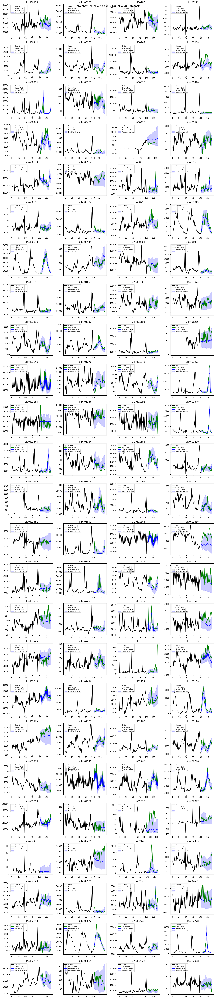

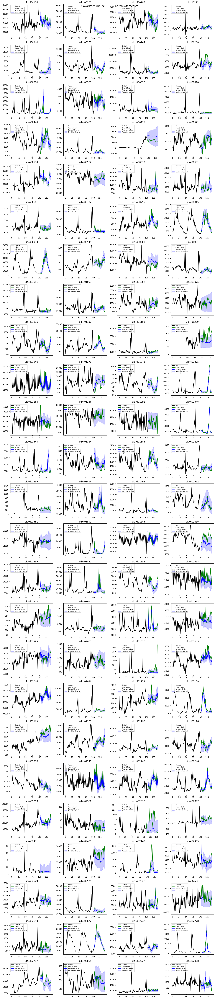

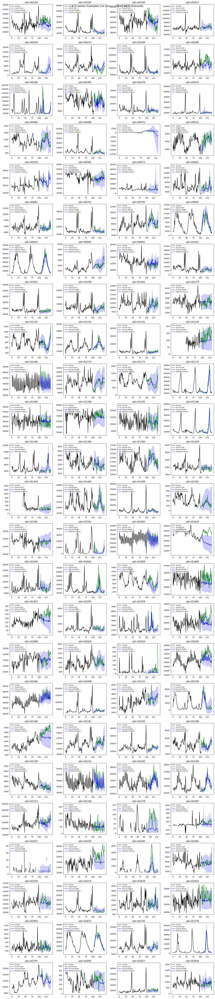

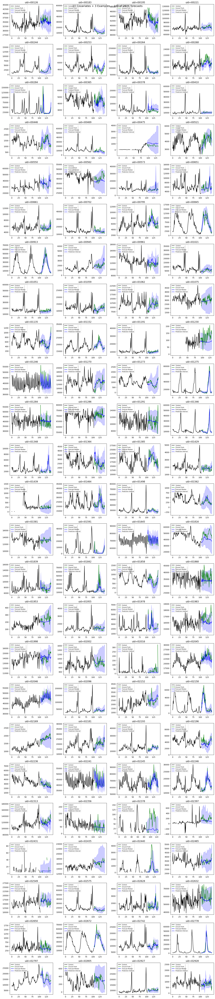

In [18]:
# One multiplot per category. Cap at MAX_PLOTS_PER_CATEGORY subplots so the
# figure stays render-able when the dataset grows to 1000s of items.
MAX_PLOTS_PER_CATEGORY = 100
_categories_viz = [
    ("Zero-shot (no cov, no ex)",         all_forecasts_zero_shot),
    ("10 Covariates (no ex)",             all_forecasts_cov),
    ("3 In-series Examples (no cov)",     all_forecasts_ex),
    ("10 Covariates + 3 Examples",        all_forecasts_cov_ex),
]
for _label, _forecasts in _categories_viz:
    _visualize_forecasts_multiplot(
        forecasts=_forecasts,
        category_name=_label,
        max_samples=MAX_PLOTS_PER_CATEGORY,
        random_seed=42,
        n_cols=4,
        display=True,
    )
